# Módulo de la Ontología

Instalar las dependencias para crear las Ontologías

In [ ]:
!pip install rdflib
!pip install owlrl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.8/55.8 kB 2.1 MB/s eta 0:00:00


In [ ]:
import rdflib
from rdflib import Graph, Namespace, URIRef, Literal
from rdflib.namespace import RDF, RDFS, XSD, FOAF, DCTERMS
from owlrl import DeductiveClosure, RDFS_Semantics

# Inicializar Grafo y Namespace
g = Graph()
EX = Namespace("http://ejemplo.org/superheroes/")

g.bind("ex", EX)
g.bind("foaf", FOAF)
g.bind("dcterms", DCTERMS)
g.bind("rdfs", RDFS)
g.bind("xsd", XSD)

print("CONSTRUCCIÓN DE LA ONTOLOGÍA\n")

# DEFINICIÓN DE CLASES (13 Clases - rdfs:label y dcterms:description)
# Se crea una lista de tuplas con el NameSpace de cada clase, un RFDS label y DCTERMS description
clases = [
    (EX.Personaje, "Personaje", "Clase raíz para entidades del universo de cómics."),
    (EX.Superheroe, "Superhéroe", "Personaje enfocado en proteger la humanidad."),
    (EX.Supervillano, "Supervillano", "Personaje antagonista que genera caos."),
    (EX.HeroeMarvel, "Héroe de Marvel", "Superhéroe de la editorial Marvel Comics."),
    (EX.HeroeDC, "Héroe de DC", "Superhéroe de la editorial DC Comics."),
    (EX.VillanoMarvel, "Villano de Marvel", "Supervillano de la editorial Marvel Comics."),
    (EX.VillanoDC, "Villano de DC", "Supervillano de la editorial DC Comics."),
    (EX.Humano, "Humano", "Personaje de origen biológico terrestre."),
    (EX.HumanoTecnologico, "Humano Tecnológico", "Humano que utiliza gadgets o tecnología sin poderes nativos."),
    (EX.HumanoMutado, "Humano Mutado", "Humano con alteración biológica o genética."),
    (EX.Alienigena, "Alienígena", "Personaje no humano proveniente del espacio exterior o reinos extra-dimensionales."),
    (EX.Superpoder, "Superpoder", "Habilidad sobrehumana o metahumana."),
    (EX.Equipamiento, "Equipamiento", "Artefacto, arma o tecnología empleada.")
]

# Se recorre la lista de tuplas por tripletas con uri, label y descripcion para añadirlo al grafo
for uri_c, label, desc in clases:
    g.add((uri_c, RDF.type, RDFS.Class))
    g.add((uri_c, RDFS.label, Literal(label)))
    g.add((uri_c, DCTERMS.description, Literal(desc)))

# Jerarquía de Clases (rdfs:subClassOf)
# Se crea la jerarquía de clases, se definen cuales son las sub clases para cada clase
g.add((EX.Superheroe, RDFS.subClassOf, EX.Personaje))
g.add((EX.Supervillano, RDFS.subClassOf, EX.Personaje))
g.add((EX.HeroeMarvel, RDFS.subClassOf, EX.Superheroe))
g.add((EX.HeroeDC, RDFS.subClassOf, EX.Superheroe))
g.add((EX.VillanoMarvel, RDFS.subClassOf, EX.Supervillano))
g.add((EX.VillanoDC, RDFS.subClassOf, EX.Supervillano))
g.add((EX.Humano, RDFS.subClassOf, EX.Personaje))
g.add((EX.HumanoTecnologico, RDFS.subClassOf, EX.Humano))
g.add((EX.HumanoMutado, RDFS.subClassOf, EX.Humano))
g.add((EX.Alienigena, RDFS.subClassOf, EX.Personaje))

# DEFINICIÓN DE PROPIEDADES (9 Propiedades: Propiedad - Dominio - Rango - rdfs:label y dcterms:description)
# Se define una lista de tuplas para cada propiedad con Su NameSpace, dominio, rango, RDFS label y DCTERMS description
props = [
    (FOAF.name, EX.Personaje, XSD.string, "Nombre Real", "Nombre civil o de identidad real (Vocabulario FOAF)."),
    (EX.tienePoder, EX.Personaje, EX.Superpoder, "Tiene Poder", "Relaciona un personaje con su habilidad innata."),
    (EX.poseeArtefacto, EX.Personaje, EX.Equipamiento, "Posee Artefacto", "Relaciona un personaje con su equipamiento."),
    (EX.esEnemigoDe, EX.Personaje, EX.Personaje, "Es Enemigo De", "Rivalidad combativa entre dos personajes."),
    (EX.usaIdentidadOculta, EX.Personaje, XSD.boolean, "Usa Identidad Oculta", "Indica si oculta su cara/identidad."),
    (EX.valorPopularidad, EX.Personaje, XSD.integer, "Valor Popularidad", "Métrica de 0 a 100 para lógica difusa."),
    (EX.valorAmenaza, EX.Personaje, XSD.integer, "Valor Amenaza", "Métrica de 0 a 10 para lógica difusa."),
    (EX.valorPoder, EX.Personaje, XSD.integer, "Valor Poder", "Métrica de 0 a 100 para lógica difusa."),
    (EX.tieneCapa, EX.Personaje, XSD.boolean, "Tiene Capa", "Indica si el personaje viste capa en su traje.")
]

for propiedad_uri, domain_uri, range_uri, label, desc in props:
    g.add((propiedad_uri, RDF.type, RDF.Property))
    g.add((propiedad_uri, RDFS.domain, domain_uri))
    g.add((propiedad_uri, RDFS.range, range_uri))
    g.add((propiedad_uri, RDFS.label, Literal(label)))
    g.add((propiedad_uri, DCTERMS.description, Literal(desc)))

# 2 subpropiedades
subprops=[
    (EX.esArchienemigoDe,  "Es Archienemigo De", "Subpropiedad para archirrivalidad histórica."),
    (EX.poseeArmaMitica,  "Posee Arma Mítica", "Subpropiedad para armas divinas/míticas.")

]
for subprop_uri , label, desc in subprops:
    g.add((subprop_uri, RDF.type, RDF.Property))
    g.add((subprop_uri, RDFS.label, Literal(label) ))
    g.add((subprop_uri, DCTERMS.description, Literal(desc)))

# Jerarquía de Propiedades (rdfs:subPropertyOf)
# Se definen las sub propiedades para cada propiedad
g.add((EX.poseeArmaMitica, RDFS.subPropertyOf, EX.poseeArtefacto))
g.add((EX.esArchienemigoDe, RDFS.subPropertyOf, EX.esEnemigoDe))


# INSTANCIACIÓN DE PODERES (13)
g.add((EX.SentidoAracnido, RDF.type, EX.Superpoder))
g.add((EX.FuerzaMejorada, RDF.type, EX.Superpoder))
g.add((EX.ControlTrueno, RDF.type, EX.Superpoder))
g.add((EX.PoderCosmico, RDF.type, EX.Superpoder))
g.add((EX.SuperVelocidad, RDF.type, EX.Superpoder))
g.add((EX.Vuelo, RDF.type, EX.Superpoder))
g.add((EX.FuerzaSobrehumana, RDF.type, EX.Superpoder))
g.add((EX.FuerzaDivina, RDF.type, EX.Superpoder))
g.add((EX.Simbionte, RDF.type, EX.Superpoder))
g.add((EX.RayosOmega, RDF.type, EX.Superpoder))
g.add((EX.ComunicacionMarina, RDF.type, EX.Superpoder))
g.add((EX.Hechiceria, RDF.type, EX.Superpoder))
g.add((EX.FactorCurativo, RDF.type, EX.Superpoder))


# EQUIPAMIENTOS (14 instancias de equipamiento - La 15 y 16 (LazoDeLaVerdad, Guantelete)
# se declarará por inferencia de caso 2 con el rango de posee artefacto)
equipamientos = [EX.ArmaduraTech, EX.ArcoGadgets, EX.EscudoVibranium, EX.Mjolnir, EX.TablaCosmica,
        EX.Batarang, EX.PlaneadorBombas, EX.TrajeAlasTech, EX.ToxinaRisa, EX.Acertijos, EX.TrajeKryptonita,
        EX.ArmaduraMisticotech, EX.TridenteDeNeptuno, EX.GarrasAdamantium]
for equipamiento in equipamientos:
    g.add((equipamiento, RDF.type, EX.Equipamiento))

# PERSONAJES (26)
# MARVEL HEROES (7)
# Wolverine
g.add((EX.Wolverine, RDF.type, EX.HeroeMarvel))
g.add((EX.Wolverine, RDF.type, EX.HumanoMutado))
g.add((EX.Wolverine, FOAF.name, Literal("Logan", datatype=XSD.string)))
g.add((EX.Wolverine, EX.poseeArtefacto, EX.GarrasAdamantium))
g.add((EX.Wolverine, EX.tienePoder, EX.FactorCurativo))
g.add((EX.Wolverine, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.Wolverine, EX.valorPopularidad, Literal(80, datatype=XSD.integer)))
g.add((EX.Wolverine, EX.valorAmenaza, Literal(6, datatype=XSD.integer)))
g.add((EX.Wolverine, EX.valorPoder, Literal(65, datatype=XSD.integer)))

# Iron Man
g.add((EX.IronMan, RDF.type, EX.HeroeMarvel))
g.add((EX.IronMan, RDF.type, EX.HumanoTecnologico))
g.add((EX.IronMan, FOAF.name, Literal("Tony Stark", datatype=XSD.string)))
g.add((EX.IronMan, EX.poseeArtefacto, EX.ArmaduraTech))
g.add((EX.IronMan, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.IronMan, EX.valorPopularidad, Literal(93, datatype=XSD.integer)))
g.add((EX.IronMan, EX.valorAmenaza, Literal(6, datatype=XSD.integer)))
g.add((EX.IronMan, EX.valorPoder, Literal(78, datatype=XSD.integer)))

# Hawkeye
g.add((EX.Hawkeye, RDF.type, EX.HeroeMarvel))
g.add((EX.Hawkeye, RDF.type, EX.HumanoTecnologico))
g.add((EX.Hawkeye, FOAF.name, Literal("Clint Barton", datatype=XSD.string)))
g.add((EX.Hawkeye, EX.poseeArtefacto, EX.ArcoGadgets))
g.add((EX.Hawkeye, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.Hawkeye, EX.valorPopularidad, Literal(76, datatype=XSD.integer)))
g.add((EX.Hawkeye, EX.valorAmenaza, Literal(3, datatype=XSD.integer)))
g.add((EX.Hawkeye, EX.valorPoder, Literal(22, datatype=XSD.integer)))

# Spider-Man
g.add((EX.SpiderMan, RDF.type, EX.HeroeMarvel))
g.add((EX.SpiderMan, RDF.type, EX.HumanoMutado))
g.add((EX.SpiderMan, FOAF.name, Literal("Peter Parker", datatype=XSD.string)))
g.add((EX.SpiderMan, EX.tienePoder, EX.SentidoAracnido))
g.add((EX.SpiderMan, EX.tienePoder, EX.FuerzaSobrehumana))
g.add((EX.SpiderMan, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.SpiderMan, EX.valorPopularidad, Literal(100, datatype=XSD.integer)))
g.add((EX.SpiderMan, EX.valorAmenaza, Literal(5, datatype=XSD.integer)))
g.add((EX.SpiderMan, EX.valorPoder, Literal(64, datatype=XSD.integer)))

# Capitan America
g.add((EX.CapitanAmerica, RDF.type, EX.HeroeMarvel))
g.add((EX.CapitanAmerica, RDF.type, EX.HumanoMutado))
g.add((EX.CapitanAmerica, FOAF.name, Literal("Steve Rogers", datatype=XSD.string)))
g.add((EX.CapitanAmerica, EX.poseeArtefacto, EX.EscudoVibranium))
g.add((EX.CapitanAmerica, EX.tienePoder, EX.FuerzaMejorada))
g.add((EX.CapitanAmerica, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.CapitanAmerica, EX.valorPopularidad, Literal(97, datatype=XSD.integer)))
g.add((EX.CapitanAmerica, EX.valorAmenaza, Literal(4, datatype=XSD.integer)))
g.add((EX.CapitanAmerica, EX.valorPoder, Literal(48, datatype=XSD.integer)))

# Thor
g.add((EX.Thor, RDF.type, EX.HeroeMarvel))
g.add((EX.Thor, RDF.type, EX.Alienigena))
g.add((EX.Thor, EX.tieneCapa, Literal(True, datatype=XSD.boolean)))
g.add((EX.Thor, FOAF.name, Literal("Thor Odinson", datatype=XSD.string)))
g.add((EX.Thor, EX.poseeArmaMitica, EX.Mjolnir))
g.add((EX.Thor, EX.tienePoder, EX.ControlTrueno))
g.add((EX.Thor, EX.tienePoder, EX.FuerzaDivina))
g.add((EX.Thor, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.Thor, EX.valorPopularidad, Literal(88, datatype=XSD.integer)))
g.add((EX.Thor, EX.valorAmenaza, Literal(7, datatype=XSD.integer)))
g.add((EX.Thor, EX.valorPoder, Literal(77, datatype=XSD.integer)))

# Silver Surfer
g.add((EX.SilverSurfer, RDF.type, EX.HeroeMarvel))
g.add((EX.SilverSurfer, RDF.type, EX.Alienigena))
g.add((EX.SilverSurfer, FOAF.name, Literal("Norrin Radd", datatype=XSD.string)))
g.add((EX.SilverSurfer, EX.poseeArmaMitica, EX.TablaCosmica))
g.add((EX.SilverSurfer, EX.tienePoder, EX.PoderCosmico))
g.add((EX.SilverSurfer, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.SilverSurfer, EX.valorPopularidad, Literal(37, datatype=XSD.integer)))
g.add((EX.SilverSurfer, EX.valorAmenaza, Literal(9, datatype=XSD.integer)))
g.add((EX.SilverSurfer, EX.valorPoder, Literal(95, datatype=XSD.integer)))


# DC HEROES (7)
# Supergirl
g.add((EX.Supergirl, RDF.type, EX.HeroeDC))
g.add((EX.Supergirl, RDF.type, EX.Alienigena))
g.add((EX.Supergirl, EX.tieneCapa, Literal(True, datatype=XSD.boolean)))
g.add((EX.Supergirl, FOAF.name, Literal("Kara Zor-El", datatype=XSD.string)))
g.add((EX.Supergirl, EX.tienePoder, EX.Vuelo))
g.add((EX.Supergirl, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.Supergirl, EX.valorPopularidad, Literal(50, datatype=XSD.integer)))
g.add((EX.Supergirl, EX.valorAmenaza, Literal(7, datatype=XSD.integer)))
g.add((EX.Supergirl, EX.valorPoder, Literal(90, datatype=XSD.integer)))

# Batman
g.add((EX.Batman, RDF.type, EX.HeroeDC))
g.add((EX.Batman, RDF.type, EX.HumanoTecnologico))
g.add((EX.Batman, EX.tieneCapa, Literal(True, datatype=XSD.boolean)))
g.add((EX.Batman, EX.esArchienemigoDe, EX.Joker))
g.add((EX.Batman, FOAF.name, Literal("Bruce Wayne", datatype=XSD.string)))
g.add((EX.Batman, EX.poseeArtefacto, EX.Batarang))
g.add((EX.Batman, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.Batman, EX.valorPopularidad, Literal(99, datatype=XSD.integer)))
g.add((EX.Batman, EX.valorAmenaza, Literal(5, datatype=XSD.integer)))
g.add((EX.Batman, EX.valorPoder, Literal(28, datatype=XSD.integer)))

# Green Arrow
g.add((EX.GreenArrow, RDF.type, EX.HeroeDC))
g.add((EX.GreenArrow, RDF.type, EX.HumanoTecnologico))
g.add((EX.GreenArrow, FOAF.name, Literal("Oliver Queen", datatype=XSD.string)))
g.add((EX.GreenArrow, EX.poseeArtefacto, EX.ArcoGadgets))
g.add((EX.GreenArrow, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.GreenArrow, EX.valorPopularidad, Literal(62, datatype=XSD.integer)))
g.add((EX.GreenArrow, EX.valorAmenaza, Literal(2, datatype=XSD.integer)))
g.add((EX.GreenArrow, EX.valorPoder, Literal(19, datatype=XSD.integer)))

# Flash
g.add((EX.Flash, RDF.type, EX.HeroeDC))
g.add((EX.Flash, RDF.type, EX.HumanoMutado))
g.add((EX.Flash, EX.esArchienemigoDe,EX.ReverseFlash))
g.add((EX.Flash, FOAF.name, Literal("Barry Allen", datatype=XSD.string)))
g.add((EX.Flash, EX.tienePoder, EX.SuperVelocidad))
g.add((EX.Flash, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.Flash, EX.valorPopularidad, Literal(70, datatype=XSD.integer)))
g.add((EX.Flash, EX.valorAmenaza, Literal(7, datatype=XSD.integer)))
g.add((EX.Flash, EX.valorPoder, Literal(85, datatype=XSD.integer)))

# Superman
g.add((EX.Superman, RDF.type, EX.HeroeDC))
g.add((EX.Superman, RDF.type, EX.Alienigena))
g.add((EX.Superman, EX.tieneCapa, Literal(True, datatype=XSD.boolean)))
g.add((EX.Superman, FOAF.name, Literal("Clark Kent", datatype=XSD.string)))
g.add((EX.Superman, EX.esArchienemigoDe, EX.LexLuthor))
g.add((EX.Superman, EX.tienePoder, EX.Vuelo))
g.add((EX.Superman, EX.tienePoder, EX.FuerzaSobrehumana))
g.add((EX.Superman, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.Superman, EX.valorPopularidad, Literal(97, datatype=XSD.integer)))
g.add((EX.Superman, EX.valorAmenaza, Literal(9, datatype=XSD.integer)))
g.add((EX.Superman, EX.valorPoder, Literal(98, datatype=XSD.integer)))

# Wonder Woman
g.add((EX.WonderWoman, RDF.type, EX.HeroeDC))
g.add((EX.WonderWoman, RDF.type, EX.HumanoMutado))
g.add((EX.WonderWoman, FOAF.name, Literal("Diana Prince", datatype=XSD.string)))
g.add((EX.WonderWoman, EX.poseeArmaMitica, EX.LazoDeLaVerdad))
g.add((EX.WonderWoman, EX.tienePoder, EX.FuerzaDivina))
g.add((EX.WonderWoman, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.WonderWoman, EX.valorPopularidad, Literal(89, datatype=XSD.integer)))
g.add((EX.WonderWoman, EX.valorAmenaza, Literal(5, datatype=XSD.integer)))
g.add((EX.WonderWoman, EX.valorPoder, Literal(60, datatype=XSD.integer)))

# Aquaman
g.add((EX.Aquaman, RDF.type, EX.HeroeDC))
g.add((EX.Aquaman, RDF.type, EX.HumanoMutado))
g.add((EX.Aquaman, FOAF.name, Literal("Arthur Curry", datatype=XSD.string)))
g.add((EX.Aquaman, EX.poseeArmaMitica, EX.TridenteDeNeptuno))
g.add((EX.Aquaman, EX.tienePoder, EX.ComunicacionMarina))
g.add((EX.Aquaman, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.Aquaman, EX.valorPopularidad, Literal(50, datatype=XSD.integer)))
g.add((EX.Aquaman, EX.valorAmenaza, Literal(6, datatype=XSD.integer)))
g.add((EX.Aquaman, EX.valorPoder, Literal(65, datatype=XSD.integer)))


# MARVEL VILLAINS (6)
# Carnage
g.add((EX.Carnage, RDF.type, EX.VillanoMarvel))
g.add((EX.Carnage, RDF.type, EX.HumanoMutado))
g.add((EX.Carnage, FOAF.name, Literal("Cletus Kasady", datatype=XSD.string)))
g.add((EX.Carnage, EX.tienePoder, EX.Simbionte))
g.add((EX.Carnage, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.Carnage, EX.valorPopularidad, Literal(50, datatype=XSD.integer)))
g.add((EX.Carnage, EX.valorAmenaza, Literal(5, datatype=XSD.integer)))
g.add((EX.Carnage, EX.valorPoder, Literal(68, datatype=XSD.integer)))

# Green Goblin
g.add((EX.GreenGoblin, RDF.type, EX.VillanoMarvel))
g.add((EX.GreenGoblin, RDF.type, EX.HumanoTecnologico))
g.add((EX.GreenGoblin, FOAF.name, Literal("Norman Osborn", datatype=XSD.string)))
g.add((EX.GreenGoblin, EX.poseeArtefacto, EX.PlaneadorBombas))
g.add((EX.GreenGoblin, EX.tienePoder, EX.FuerzaMejorada))
g.add((EX.GreenGoblin, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.GreenGoblin, EX.valorPopularidad, Literal(69, datatype=XSD.integer)))
g.add((EX.GreenGoblin, EX.valorAmenaza, Literal(5, datatype=XSD.integer)))
g.add((EX.GreenGoblin, EX.valorPoder, Literal(55, datatype=XSD.integer)))

# Vulture
g.add((EX.Vulture, RDF.type, EX.VillanoMarvel))
g.add((EX.Vulture, RDF.type, EX.HumanoTecnologico))
g.add((EX.Vulture, FOAF.name, Literal("Adrian Toomes", datatype=XSD.string)))
g.add((EX.Vulture, EX.poseeArtefacto, EX.TrajeAlasTech))
g.add((EX.Vulture, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.Vulture, EX.valorPopularidad, Literal(25, datatype=XSD.integer)))
g.add((EX.Vulture, EX.valorAmenaza, Literal(2, datatype=XSD.integer)))
g.add((EX.Vulture, EX.valorPoder, Literal(21, datatype=XSD.integer)))

# Venom
g.add((EX.Venom, RDF.type, EX.VillanoMarvel))
g.add((EX.Venom, RDF.type, EX.HumanoMutado))
g.add((EX.Venom, FOAF.name, Literal("Eddie Brock", datatype=XSD.string)))
g.add((EX.Venom, EX.tienePoder, EX.Simbionte))
g.add((EX.Venom, EX.tienePoder, EX.FuerzaSobrehumana))
g.add((EX.Venom, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.Venom, EX.valorPopularidad, Literal(79, datatype=XSD.integer)))
g.add((EX.Venom, EX.valorAmenaza, Literal(7, datatype=XSD.integer)))
g.add((EX.Venom, EX.valorPoder, Literal(74, datatype=XSD.integer)))

# Thanos
g.add((EX.Thanos, RDF.type, EX.VillanoMarvel))
g.add((EX.Thanos, RDF.type, EX.Alienigena))
g.add((EX.Thanos, FOAF.name, Literal("Thanos", datatype=XSD.string)))
g.add((EX.Thanos, EX.poseeArmaMitica, EX.Guantelete))
g.add((EX.Thanos, EX.tienePoder, EX.FuerzaSobrehumana))
g.add((EX.Thanos, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.Thanos, EX.valorPopularidad, Literal(89, datatype=XSD.integer)))
g.add((EX.Thanos, EX.valorAmenaza, Literal(10, datatype=XSD.integer)))
g.add((EX.Thanos, EX.valorPoder, Literal(96, datatype=XSD.integer)))

# Doctor Doom
g.add((EX.DoctorDoom, RDF.type, EX.VillanoMarvel))
g.add((EX.DoctorDoom, RDF.type, EX.HumanoTecnologico))
g.add((EX.DoctorDoom, EX.tieneCapa, Literal(True, datatype=XSD.boolean)))
g.add((EX.DoctorDoom, FOAF.name, Literal("Victor von Doom", datatype=XSD.string)))
g.add((EX.DoctorDoom, EX.poseeArtefacto, EX.ArmaduraMisticotech))
g.add((EX.DoctorDoom, EX.tienePoder, EX.Hechiceria))
g.add((EX.DoctorDoom, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.DoctorDoom, EX.valorPopularidad, Literal(90, datatype=XSD.integer)))
g.add((EX.DoctorDoom, EX.valorAmenaza, Literal(9, datatype=XSD.integer)))
g.add((EX.DoctorDoom, EX.valorPoder, Literal(90, datatype=XSD.integer)))

# DC VILLAINS (6)
# General Zod
g.add((EX.GeneralZod, RDF.type, EX.VillanoDC))
g.add((EX.GeneralZod, RDF.type, EX.Alienigena))
g.add((EX.GeneralZod, EX.tieneCapa, Literal(True, datatype=XSD.boolean)))
g.add((EX.GeneralZod, FOAF.name, Literal("Dru-Zod", datatype=XSD.string)))
g.add((EX.GeneralZod, EX.tienePoder, EX.Vuelo))
g.add((EX.GeneralZod, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.GeneralZod, EX.valorPopularidad, Literal(80, datatype=XSD.integer)))
g.add((EX.GeneralZod, EX.valorAmenaza, Literal(7, datatype=XSD.integer)))
g.add((EX.GeneralZod, EX.valorPoder, Literal(70, datatype=XSD.integer)))

# Joker
g.add((EX.Joker, RDF.type, EX.VillanoDC))
g.add((EX.Joker, RDF.type, EX.HumanoTecnologico))
g.add((EX.Joker, FOAF.name, Literal("Desconocido", datatype=XSD.string)))
g.add((EX.Joker, EX.esArchienemigoDe, EX.Batman))
g.add((EX.Joker, EX.poseeArtefacto, EX.ToxinaRisa))
g.add((EX.Joker, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.Joker, EX.valorPopularidad, Literal(95, datatype=XSD.integer)))
g.add((EX.Joker, EX.valorAmenaza, Literal(3, datatype=XSD.integer)))
g.add((EX.Joker, EX.valorPoder, Literal(14, datatype=XSD.integer)))

# Riddler
g.add((EX.Riddler, RDF.type, EX.VillanoDC))
g.add((EX.Riddler, RDF.type, EX.HumanoTecnologico))
g.add((EX.Riddler, FOAF.name, Literal("Edward Nygma", datatype=XSD.string)))
g.add((EX.Riddler, EX.poseeArtefacto, EX.Acertijos))
g.add((EX.Riddler, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.Riddler, EX.valorPopularidad, Literal(60, datatype=XSD.integer)))
g.add((EX.Riddler, EX.valorAmenaza, Literal(2, datatype=XSD.integer)))
g.add((EX.Riddler, EX.valorPoder, Literal(9, datatype=XSD.integer)))

# Reverse Flash
g.add((EX.ReverseFlash, RDF.type, EX.VillanoDC))
g.add((EX.ReverseFlash, EX.esArchienemigoDe,EX.Flash))
g.add((EX.ReverseFlash, RDF.type, EX.HumanoMutado))
g.add((EX.ReverseFlash, FOAF.name, Literal("Eobard Thawne", datatype=XSD.string)))
g.add((EX.ReverseFlash, EX.tienePoder, EX.SuperVelocidad))
g.add((EX.ReverseFlash, EX.usaIdentidadOculta, Literal(True, datatype=XSD.boolean)))
g.add((EX.ReverseFlash, EX.valorPopularidad, Literal(58, datatype=XSD.integer)))
g.add((EX.ReverseFlash, EX.valorAmenaza, Literal(8, datatype=XSD.integer)))
g.add((EX.ReverseFlash, EX.valorPoder, Literal(88, datatype=XSD.integer)))

# Darkseid
g.add((EX.Darkseid, RDF.type, EX.VillanoDC))
g.add((EX.Darkseid, RDF.type, EX.Alienigena))
g.add((EX.Darkseid, FOAF.name, Literal("Uxas", datatype=XSD.string)))
g.add((EX.Darkseid, EX.tienePoder, EX.RayosOmega))
g.add((EX.Darkseid, EX.tienePoder, EX.FuerzaDivina))
g.add((EX.Darkseid, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.Darkseid, EX.valorPopularidad, Literal(63, datatype=XSD.integer)))
g.add((EX.Darkseid, EX.valorAmenaza, Literal(10, datatype=XSD.integer)))
g.add((EX.Darkseid, EX.valorPoder, Literal(100, datatype=XSD.integer)))

# Lex Luthor
g.add((EX.LexLuthor, RDF.type, EX.VillanoDC))
g.add((EX.LexLuthor, RDF.type, EX.HumanoTecnologico))
g.add((EX.LexLuthor, FOAF.name, Literal("Lex Luthor", datatype=XSD.string)))
g.add((EX.LexLuthor, EX.esArchienemigoDe, EX.Superman))
g.add((EX.LexLuthor, EX.poseeArtefacto, EX.TrajeKryptonita))
g.add((EX.LexLuthor, EX.usaIdentidadOculta, Literal(False, datatype=XSD.boolean)))
g.add((EX.LexLuthor, EX.valorPopularidad, Literal(89, datatype=XSD.integer)))
g.add((EX.LexLuthor, EX.valorAmenaza, Literal(5, datatype=XSD.integer)))
g.add((EX.LexLuthor, EX.valorPoder, Literal(63, datatype=XSD.integer)))

tripletas_antes = len(g)
print(f"Total de tripletas explícitas ingresadas: {tripletas_antes}\n")

print("Evidencia casos antes del motor de inferencia")
c1_1 = (EX.Thor, RDF.type, EX.Superheroe) in g
c1_2 = (EX.Superman, RDF.type, EX.Personaje) in g
print(f"Caso 1: \nTripletas inferidas por jerarquía de clase")
print(f"Thor RDF:type SuperHeroe -> Inferido de Thor RDF:type HeroeMarvel  {c1_1}")
print(f"Superman RDF:type Personaje -> Inferido de Superman RDF:type HeroeDC {c1_2}\n")

c2_dom = (EX.WonderWoman, RDF.type, EX.Personaje) in g
c2_ran = (EX.LazoDeLaVerdad, RDF.type, EX.Equipamiento) in g
print(f"Caso 2: \nTripletas inferidas por Domain / Range")
print(f"WonderWoman poseeArtefacto LazoDeLaVerdad (Sin tipos explícitos)")
print(f"-> Inferido Dominio: WonderWoman es Personaje: {c2_dom}")
print(f"-> Inferido Rango: LazoDeLaVerdad es Equipamiento: {c2_ran}\n")

c3_1 = (EX.Thor, EX.poseeArtefacto, EX.Mjolnir) in g
c3_2 = (EX.Joker, EX.esEnemigoDe, EX.Batman) in g
print("Caso 3: \nTripletas inferidas por jerarquía de propiedades")
print(f"Thor poseeArtefacto Mjolnir -> Inferido de Thor poseeArmaMitica Mjolnir: {c3_1}")
print(f"Joker esEnemigoDe Batman -> Inferido de Joker EsArchienemigoDe Batman: {c3_2}\n")

# Activación motor de inferencia (OWL-RL)
print("Aplicando el motor de inferencia (DeductiveClosure - RDFS_Semantics)")

DeductiveClosure(RDFS_Semantics).expand(g)
tripletas_despues = len(g)

print(f"Tripletas antes del razonamiento:  {tripletas_antes}")
print(f"Tripletas después del razonamiento: {tripletas_despues}")
print(f"Nuevas afirmaciones inferidas: {tripletas_despues - tripletas_antes}\n")

# Documentación de casos
print("Documentación casos")

# Caso 1: Jerarquía de clases (subClassOf) - 2 Casos
c1_1 = (EX.Thor, RDF.type, EX.Superheroe) in g
c1_2 = (EX.Superman, RDF.type, EX.Personaje) in g
print(f"Caso 1: \nTripletas inferidas por jerarquía de clase")
print(f"Thor RDF:type SuperHeroe -> Inferido de Thor RDF:type HeroeMarvel  {c1_1}")
print(f"Superman RDF:type Personaje -> Inferido de Superman RDF:type HeroeDC {c1_2}\n")

# CASO 2: Inferencia desde Domain / Range
c2_dom = (EX.WonderWoman, RDF.type, EX.Personaje) in g
c2_ran = (EX.LazoDeLaVerdad, RDF.type, EX.Equipamiento) in g
print(f"Caso 2: \nTripletas inferidas por Domain / Range")
print(f"WonderWoman poseeArtefacto LazoDeLaVerdad (Sin tipos explícitos)")
print(f"-> Inferido Dominio: WonderWoman es Personaje: {c2_dom}")
print(f"-> Inferido Rango: LazoDeLaVerdad es Equipamiento: {c2_ran}\n")

# CASO 3: Jerarquía de Propiedades (subPropertyOf)
c3_1 = (EX.Thor, EX.poseeArtefacto, EX.Mjolnir) in g
c3_2 = (EX.Joker, EX.esEnemigoDe, EX.Batman) in g
print("Caso 3: \nTripletas inferidas por jerarquía de propiedades")
print(f"Thor poseeArtefacto Mjolnir -> Inferido de Thor poseeArmaMitica Mjolnir: {c3_1}")
print(f"Joker esEnemigoDe Batman -> Inferido de Joker EsArchienemigoDe Batman: {c3_2}\n")

# Evidencia de los 4 hechos inferidos automáticamente por el razonador
print("Evidencia de los 4 hechos inferidos automáticamente por el razonador")
hechos_ejemplo = [
    ("ex:Superman", "rdf:type", "ex:Personaje", "Inferido por subclase ex:Alienigena"),
    ("ex:Thanos", "rdf:type", "ex:Personaje", "Inferido por subclase ex:VillanoMarvel"),
    ("ex:IronMan", "rdf:type", "ex:Humano", "Inferido por subclase ex:HumanoTecnologico"),
    ("ex:Guantelete", "rdf:type", "ex:Equipamiento", "Inferido por subpropiedad ex:poseeArmaMitica")
]

for idx, (s, p, o, razon) in enumerate(hechos_ejemplo, start=1):
    print(f"Hecho Inferido {idx}: ({s} {p} {o})")
    print(f"Justificación: {razon}\n")


# Serialización en Turtle
archivo_ontologia = "ontologia_generada.ttl"
g.serialize(destination=archivo_ontologia, format="turtle")
print(f"Ontología serializada correctamente en '{archivo_ontologia}'")
print("Ir al final de documento para ver donde quedo guardado en tu drive")

CONSTRUCCIÓN DE LA ONTOLOGÍA

Total de tripletas explícitas ingresadas: 363

Evidencia casos antes del motor de inferencia
Caso 1: 
Tripletas inferidas por jerarquía de clase
Thor RDF:type SuperHeroe -> Inferido de Thor RDF:type HeroeMarvel  False
Superman RDF:type Personaje -> Inferido de Superman RDF:type HeroeDC False

Caso 2: 
Tripletas inferidas por Domain / Range
WonderWoman poseeArtefacto LazoDeLaVerdad (Sin tipos explícitos)
-> Inferido Dominio: WonderWoman es Personaje: False
-> Inferido Rango: LazoDeLaVerdad es Equipamiento: False

Caso 3: 
Tripletas inferidas por jerarquía de propiedades
Thor poseeArtefacto Mjolnir -> Inferido de Thor poseeArmaMitica Mjolnir: False
Joker esEnemigoDe Batman -> Inferido de Joker EsArchienemigoDe Batman: False

Aplicando el motor de inferencia (DeductiveClosure - RDFS_Semantics)
Tripletas antes del razonamiento:  363
Tripletas después del razonamiento: 781
Nuevas afirmaciones inferidas: 418

Documentación casos
Caso 1: 
Tripletas inferidas por 

# Módulo de Lógica Difusa

Instalar las dependencias para crear la lógica difusa




In [ ]:
!pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 13.7 MB/s eta 0:00:00


In [ ]:
import numpy as np
import skfuzzy as fuzzy
from skfuzzy import control as ctrl

# Definición del universo alineado con las propiedades de la ontología
#Variable de entrada
poder = ctrl.Antecedent(np.arange(0, 101, 1), 'poder')
amenaza = ctrl.Antecedent(np.arange(0, 11, 1), 'amenaza')
popularidad = ctrl.Antecedent(np.arange(0, 101, 1), 'popularidad')

#Variable de salida
perfil_impacto = ctrl.Consequent(np.arange(0, 101, 1), 'perfil_impacto')

#Funciones de pertenencia y modificadores
#Variables de entrada
poder['Bajo'] =  fuzzy.trimf(poder.universe, [0, 0, 35])
poder['Medio'] = fuzzy.trapmf(poder.universe, [25, 35, 65, 70])
poder['Alto'] =  fuzzy.gaussmf(poder.universe, 100, 12)
poder['Muy_Alto'] = poder['Alto'].mf**2  # Modificador de concentración
poder['Ligeramente_Alto'] = np.sqrt(poder['Alto'].mf)  # Modificador de dilatación

amenaza['Baja'] = fuzzy.trapmf(amenaza.universe, [0, 0, 2, 3])
amenaza['Media'] = fuzzy.gaussmf(amenaza.universe, 5, 1)
amenaza['Alta'] = fuzzy.trimf(amenaza.universe, [7, 10, 10])
amenaza['Muy_Alta'] = amenaza['Alta'].mf**2 # Modificador de concentración
amenaza['Ligeramente_Alta'] = np.sqrt(amenaza['Alta'].mf) # Modificador de dilatación

popularidad['Baja'] = fuzzy.trimf(popularidad.universe, [0, 0, 30])
popularidad['Media'] = fuzzy.gaussmf(popularidad.universe, 50, 10)
popularidad['Alta'] =  fuzzy.trapmf(popularidad.universe, [70, 80, 100, 100])
popularidad['Muy_Alta'] = popularidad['Alta'].mf**2 # Modificador de concentración

# Usado para desempatar 2 personajes al final
# Variable de salida
perfil_impacto['Callejero'] = fuzzy.trapmf(perfil_impacto.universe, [0, 0, 10, 30])
perfil_impacto['Global'] = fuzzy.trimf(perfil_impacto.universe, [30, 50, 70])
perfil_impacto['Cosmico'] = fuzzy.gaussmf(perfil_impacto.universe, 100, 7)

# Reglas difusas
reglas_difusas = [
    # Regla 1: Intersección (AND)
    ctrl.Rule(poder['Bajo'] & amenaza['Baja'], perfil_impacto['Callejero']),

    # Regla 2: Intersección (AND) con Modificadores ("Muy")
    ctrl.Rule(poder['Muy_Alto'] & amenaza['Muy_Alta'], perfil_impacto['Cosmico']),

    # Regla 3: Intersección (AND) y Unión (OR) combinadas
    ctrl.Rule(popularidad['Alta'] & (poder['Medio'] | amenaza['Media']), perfil_impacto['Global']),

    # Regla 4: Negación (NOT ~) + Intersección (AND)
    ctrl.Rule(~popularidad['Alta'] & poder['Bajo'], perfil_impacto['Callejero']),

    # Regla 5: Unión (OR) con Modificadores ("Ligeramente" y "Muy")
    ctrl.Rule(poder['Ligeramente_Alto'] | popularidad['Muy_Alta'], perfil_impacto['Global']),

    # Regla 6: Intersección (AND) y Negación (NOT ~)
    ctrl.Rule(amenaza['Alta'] & ~poder['Bajo'], perfil_impacto['Cosmico']),

    # Regla 7: Intersección (AND)
    ctrl.Rule(poder['Medio'] & popularidad['Baja'], perfil_impacto['Callejero']),

    # Regla 8: Intersección (AND) con Modificador en amenaza
    ctrl.Rule(popularidad['Alta'] & amenaza['Muy_Alta'], perfil_impacto['Cosmico']),

    # Regla 9: Múltiple Negación (NOT ~) e Intersección (AND)
    ctrl.Rule(~amenaza['Alta'] & ~poder['Alto'] & popularidad['Media'], perfil_impacto['Global'])
]

# Creación del sistema con la lista de Reglas difusas
sistema_control_difuso = ctrl.ControlSystem(reglas_difusas)

# Esta función toma los valores de poder, amenaza y popularidad de los personajes restantes
# en el desempate difuso y los valores ingresados por el usuario
def evaluar_perfil_difuso(v_poder, v_amenaza, v_popularidad):
    # Ejecuta la inferencia difusa y retorna la defuzzificación por Centroide (0 a 100).
    simulador = ctrl.ControlSystemSimulation(sistema_control_difuso)
    simulador.input['poder'] = float(v_poder)
    simulador.input['amenaza'] = float(v_amenaza)
    simulador.input['popularidad'] = float(v_popularidad)
    simulador.compute()
    return simulador.output['perfil_impacto']

# Ejemplo de prueba rápida en la celda:
score_ejemplo = evaluar_perfil_difuso(64, 5, 100)
print(f"Spiderman {score_ejemplo}")

Spiderman 49.99999999999999


# Módulo de Sistema Experto

Instalar las dependencias para crear el sistema experto

In [ ]:
!pip install experta

  Preparing metadata (setup.py) ... done
  Created wheel for frozendict: filename=frozendict-1.2-py3-none-any.whl size=3216 sha256=e2f3ef98b18ddd2de4adc6384d018059df5ae2ff9581332d734feb5fe00ea11a
  Stored in directory: /root/.cache/pip/wheels/9d/52/17/c157159b12f1f628db6d6a19a4bfa5ffd670095803800543fb
Successfully built frozendict
  Attempting uninstall: frozendict
    Found existing installation: frozendict 2.4.7
    Uninstalling frozendict-2.4.7:
      Successfully uninstalled frozendict-2.4.7
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
yfinance 0.2.66 requires frozendict>=2.3.4, but you have frozendict 1.2 which is incompatible.


In [ ]:
import collections.abc
if not hasattr(collections, 'Mapping'):
    collections.Mapping = collections.abc.Mapping

In [ ]:
from experta import *
from rdflib import Graph, URIRef, Namespace, Literal
from rdflib.namespace import RDF, RDFS, XSD, FOAF, DCTERMS
import random
import re


# Traducción de la ontología para traer los datos al sistema experto
g = Graph()
g.parse("ontologia_generada.ttl", format="turtle")
EX = Namespace("http://ejemplo.org/superheroes/")

# La función n_local toma un uri completo, a través de
# la función split toma el nombre local y lo retorna
def n_local(uri):
    return uri.split("/")[-1]

# Esta función toma un string le quita las tildes y le quita los espacios en blanco remplazandolos con una cadena vacia
def normalize(s):
    s = s.replace(" ", "").lower()
    replacements = (
        ("á", "a"),
        ("é", "e"),
        ("í", "i"),
        ("ó", "o"),
        ("ú", "u"),
    )
    for a, b in replacements:
        s = s.replace(a, b)

    return s

clase=set()
propiedad=set()

# Agregamos los nombres de las clases y propiedades a sus sets respectivos
for s,p,o in g.triples((None,RDF.type,RDFS.Class)):
    clase.add(n_local(s))

for s,p,o in g.triples((None,RDF.type,RDF.Property)) :
    s_literal=n_local(s)

    if "#" not in s_literal and ('/dc' not in s):
        propiedad.add(s_literal)


dict_personajes={}
# Este es el traductor de la ontología.
# El primer ciclo for nos sirve para sacar los nombres de los personajes.
# El segundo ciclo for toma el uri del recurso y evalua las tripletas que tengan como sujeto al personajes obtenido en el primer ciclo for
#
# Ejm:
# Del primer for se obtiene el uri http://ejemplo.org/superheroes/SpiderMan, luego lee "SpiderMan" y si no se encuentra en dict_personajes,
# lo agrega con un value que es un diccionario de la forma {'uri':'SpiderMan'}.

# El segundo for evalúa las tripletas que tengan sujeto http://ejemplo.org/superheroes/SpiderMan.

# Luego, el código evalúa que su predicado u objeto se encuentren en los sets propiedad y clase respectivamente (Como queremos obtener las clases y las propiedades de ese sujeto, es necesario
# mirar el predicado para una tripleta de propiedad y el objeto para una tripleta de clase).
# Posteriormente evalúa las restricciones y agrega esa propiedad o clase al diccionario de ese
# personaje con value True si se encuentra asociado a este. ej. {Spiderman:{"uri":Spiderman, "name":Peter Parker, "tienePoder":True}}.
#Adicionalmente, las únicas clases/propiedades que sí guardan su instancia como value en el diccionario del personaje son: FOAF.name, EX.usaIdentidadOculta (qué también es boolean),
#EX.valorPopularidad, EX.valorAmenaza y EX.valorPoder.
# Por último, si el personaje no tiene alguna de las propiedades/clases, estas se instanciarán en el diccionario con un value Boolean(False)

for s,p,o in g.triples((None,RDF.type,EX.Personaje)):
    s_literal=n_local(s)
    if s_literal not in dict_personajes:
        dict_personajes[s_literal]={"uri": s_literal}

        for su,pe,ob in g.triples((s, None, None)):
            pe_literal=n_local(pe)
            ob_literal=n_local(ob)

            if pe_literal in clase.union(propiedad) or ob_literal in clase.union(propiedad):

                if isinstance(ob, Literal) and ob.datatype == XSD.integer:
                    dict_personajes[s_literal][pe_literal]= int(ob_literal)

                elif pe == FOAF.name:
                    dict_personajes[s_literal][pe_literal]=ob.value

                elif isinstance(ob, Literal) and ob.datatype == XSD.boolean:
                    dict_personajes[s_literal][pe_literal]=ob.value

                elif pe==RDF.type :dict_personajes[s_literal][ob_literal]= True

                else: dict_personajes[s_literal][pe_literal]= True


        for i in clase.union(propiedad):
            if str(i) not in dict_personajes[s_literal]:
                dict_personajes[s_literal][i] = False

# Aqui se tienen todas las preguntas posibles que el sistema de adivinanza puede hacer al usuario
preguntas_akinator=["¿Tu personaje es archienemigo de algún personaje de la lista? (Enemigo recurrente en series/películas)",
                    "¿Tu personaje es un villano Marvel?",
                    "¿Tu personaje es un villano DC?",
                    "¿Tu personaje es un humano Mutado? (Nació humano, pero adquirió poderes)",
                    "¿Tu personaje es un Superhéroe?",
                    "¿Tu personaje es un Supervillano?",
                    "¿Es un Héroe Marvel?",
                    "¿Es un Héroe DC?",
                    "¿Tu personaje es de especie Humano?",
                    "¿Es un humano tecnológico?  (Usa la tecnología a su favor)",
                    "¿Tu personaje es Alienígena? (No nació en la Tierra)",
                    "¿Tiene poder alguno? (Superfuerza, Supervelocidad, etc..)",
                    "¿Posee artefacto o equipo alguno (traje, arco, martillo, lazo, etc..)?",
                    "¿Tu personaje usa identidad oculta?",
                    "¿Tu personaje tiene capa?"]

clases_dic= {}
propiedades_dic={}
preguntas_procesadas=set()

# Este ciclo for recorre la union de ambos sets y asocia las propiedades/clase a su pregunta correspondiente
for elemento in sorted(clase.union(propiedad),key=len,reverse=True): #agregue esto para que Humano no tuviera conflicto con otras preguntas
    if elemento == 'Personaje': continue
    elemento_comparacion = elemento.lower()
    for pregunta in preguntas_akinator:
        pregunta_comparacion = normalize(pregunta)
        if pregunta in preguntas_procesadas: continue
        if elemento_comparacion in pregunta_comparacion:
            preguntas_procesadas.add(pregunta)
            if elemento in clase :clases_dic[elemento] = {"uri":elemento, "pregunta":pregunta}
            else: propiedades_dic[elemento]={"uri":elemento, "pregunta":pregunta}


# Clases de Hechos
class Personaje(Fact):
    """Candidato a ser el personaje a adivinar en la base de conocimientos"""
    pass

class Respuesta(Fact):
    """La respuesta actual dada por el usuario"""
    pass

class AtributoEvaluado(Fact):
    """Historial para no hacer las mismas preguntas"""
    pass

class EstadoJuego(Fact):
    """Control de fase de inferencia"""
    pass

class PerfilDifuso(Fact):
    """Almacena las métricas de desempate y dispara la regla difusas"""
    pass

class Clase(Fact):
    """Declara las clases de cada personaje"""
    pass
class Propiedad(Fact):
    """Declara las propiedades de cada personaje"""
    pass

# Sistema experto

class Akinator(KnowledgeEngine):



    @Rule(EstadoJuego(fase="descarte"),
        OR(Clase(uri=MATCH.attr, pregunta=MATCH.p), Propiedad(uri=MATCH.attr, pregunta=MATCH.p)),
        NOT(AtributoEvaluado(nombre=MATCH.attr)),
        salience=5)
    def descarte_preguntas(self, attr, p):
        print(p)
        respuesta=input("Sí (1) o No (0): ")
        self.declare(Respuesta(atributo=attr, valor=bool(int(respuesta))))


    @Rule(AS.r << Respuesta(atributo=MATCH.attr), AS.e << EstadoJuego(fase="descarte"), salience=7)
    def eliminar_respuesta(self, r, e, attr):
        self.declare(AtributoEvaluado(nombre=attr))
        self.retract(r)
        candidatos_restantes = [fact for fact in self.facts.values() if isinstance(fact, Personaje)]
        if len(candidatos_restantes) <= 2:
            self.retract(e)
            self.declare(EstadoJuego(fase="final", candidatos=candidatos_restantes))


    # Dependiendo de la cantidad de los personajes restantes despues de la ronda de preguntas, el sistema tomara distintos caminos:
    # -Si solo queda un personaje el sistema lo imprimirá en pantalla automáticamente y el juego se dará por terminado
    # -Si no queda ningún personaje en la lista se imprimirá en pantalla que no pudo adivinar el personaje
    # -Si quedan 2 personajes entrar en fase de desempate utilizando el sistema difuso para desempatar
    @Rule(EstadoJuego(fase="final", candidatos=MATCH.candidatos_restantes),
           NOT(EstadoJuego(fase="desempate")),
           salience = 15)  # no-loop
    def decision_final(self, candidatos_restantes):
        if len(candidatos_restantes) == 1:
             cand = candidatos_restantes[0]
             print(f"\nEl motor determinó que es: {cand['uri'].upper()}")

        elif len(candidatos_restantes) == 0:
            print("\nNo se encontró un personaje con estos atributos ")

        elif len(candidatos_restantes) == 2:
             print(f"\nQuedan {len(candidatos_restantes)} candidatos. Activando lógica difusa...")
             self.declare(EstadoJuego(fase="desempate", candidatos=candidatos_restantes))
             try:
                       print("0-35: Débil (Humanos un poquito más poderosos)\n25-70: Medio poderoso (Armas avanzadas y sobrehumanos) \n60-100: Poderoso (Universal)")
                       v_pod = float(input("¿Nivel de PODER (0 a 100)?: \n"))

                       print("\nPiense en amenaza como, si el personaje fuera(o es) malo , que tanta magnitud destruiría")
                       print("0-3: Baja (Amenaza ciudades)\n3-7: Media (Amenaza el mundo)\n7-10: Alta (Amenaza el universo)")
                       v_ame = float(input("¿Nivel de AMENAZA (0 a 10)?: \n"))


                       print("\n0-30: Poco Popular \n30-70: Medio conocido \n70-100: ícono, muy conocido")
                       v_pop = float(input("¿Nivel de POPULARIDAD (0 a 100)?: \n"))
                        #Se llama a la función evaluar_perfil_difuso y toma como parametros los valores ingresados por el usuario
                        #y se declara un hecho PerfilDifuso con el valor desfuzzificado de impacto esperado, el cual será utilizado en la regla de desempate
                       self.declare(PerfilDifuso(impacto_esperado=evaluar_perfil_difuso(v_pod, v_ame, v_pop)))


             except ValueError:
                    print("\nEntrada inválida. Ingresa solo números.")

    @Rule(EstadoJuego(fase="desempate", candidatos=MATCH.candidatos_restantes),
          PerfilDifuso(impacto_esperado=MATCH.impacto_esperado))
    def desempate(self,candidatos_restantes, impacto_esperado):
        mejor_candidato = None
        menor_dif = float('inf')
        for cand in candidatos_restantes:
            # Extraemos los valores del Fact de Experta
            impacto_cand = evaluar_perfil_difuso(
                cand['valorPoder'],
                cand['valorAmenaza'],
                cand['valorPopularidad']
            )

            # El personaje que tenga la menor diferencia de impacto es el ganador
            if abs(impacto_esperado - impacto_cand) < menor_dif:
                menor_dif = abs(impacto_esperado - impacto_cand)
                mejor_candidato = cand

        if mejor_candidato:
            print(f"\nLa Lógica Difusa desempató a favor de: {mejor_candidato['uri'].upper()}\n")


    # REGLAS DE DESCARTE (Salience 10 - Se ejecutan antes de limpiar)
    @Rule(AS.r << Respuesta(atributo="Superheroe", valor=True), AS.c << Personaje(Superheroe=False), salience=10)
    def desc_no_superheroe(self, c):
        self.retract(c)

        self.declare(AtributoEvaluado(nombre="VillanoDC"))
        self.declare(AtributoEvaluado(nombre="VillanoMarvel"))
        self.declare(AtributoEvaluado(nombre="Supervillano"))

    @Rule(Respuesta(atributo="Superheroe", valor=False), AS.c << Personaje(Superheroe=True), salience=10)
    def desc_si_superheroe(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="Supervillano", valor=True), AS.c << Personaje(Supervillano=False), salience=10)
    def desc_no_supervillano(self, c):
        self.retract(c)


        self.declare(AtributoEvaluado(nombre="Superheroe"))
        self.declare(AtributoEvaluado(nombre="HeroeMarvel"))
        self.declare(AtributoEvaluado(nombre="HeroeDC"))

    @Rule(Respuesta(atributo="Supervillano", valor=False), AS.c << Personaje(Supervillano=True), salience=10)
    def desc_si_supervillano(self, c):
        self.retract(c)


    @Rule(Respuesta(atributo="HeroeMarvel", valor=True), AS.c << Personaje(HeroeMarvel=False), salience=10)
    def desc_no_hm(self, c):
        self.retract(c)

        self.declare(AtributoEvaluado(nombre="Supervillano"))
        self.declare(AtributoEvaluado(nombre="VillanoDC"))
        self.declare(AtributoEvaluado(nombre="VillanoMarvel"))
        self.declare(AtributoEvaluado(nombre="HeroeDC"))
        self.declare(AtributoEvaluado(nombre="Superheroe"))

    @Rule(Respuesta(atributo="HeroeMarvel", valor=False), AS.c << Personaje(HeroeMarvel=True), salience=10)
    def desc_si_hm(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="HeroeDC", valor=True), AS.c << Personaje(HeroeDC=False), salience=10)
    def desc_no_hdc(self, c):
        self.retract(c)

        self.declare(AtributoEvaluado(nombre="Supervillano"))
        self.declare(AtributoEvaluado(nombre="Superheroe"))
        self.declare(AtributoEvaluado(nombre="HeroeMarvel"))
        self.declare(AtributoEvaluado(nombre="VillanoMarvel"))
        self.declare(AtributoEvaluado(nombre="VillanoDC"))

    @Rule(Respuesta(atributo="HeroeDC", valor=False), AS.c << Personaje(HeroeDC=True), salience=10)
    def desc_si_hdc(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="VillanoMarvel", valor=True), AS.c << Personaje(VillanoMarvel=False), salience=10)
    def desc_no_villanomarvel(self, c):
        self.retract(c)

        self.declare(AtributoEvaluado(nombre="Supervillano"))
        self.declare(AtributoEvaluado(nombre="Superheroe"))
        self.declare(AtributoEvaluado(nombre="HeroeMarvel"))
        self.declare(AtributoEvaluado(nombre="HeroeDC"))
        self.declare(AtributoEvaluado(nombre="VillanoDC"))

    @Rule(Respuesta(atributo="VillanoMarvel", valor=False), AS.c << Personaje(VillanoMarvel=True), salience=10)
    def desc_si_villanomarvel(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="VillanoDC", valor=True), AS.c << Personaje(VillanoDC=False), salience=10)
    def desc_no_villanodc(self, c):
        self.retract(c)

        self.declare(AtributoEvaluado(nombre="Supervillano"))
        self.declare(AtributoEvaluado(nombre="Superheroe"))
        self.declare(AtributoEvaluado(nombre="HeroeMarvel"))
        self.declare(AtributoEvaluado(nombre="HeroeDC"))
        self.declare(AtributoEvaluado(nombre="VillanoMarvel"))

    @Rule(Respuesta(atributo="VillanoDC", valor=False), AS.c << Personaje(VillanoDC=True), salience=10)
    def desc_si_villanodc(self, c):
        self.retract(c)


    @Rule(Respuesta(atributo="Humano", valor=True), AS.c << Personaje(Humano=False), salience=10)
    def desc_no_humano(self, c):
        self.retract(c)

        self.declare(AtributoEvaluado(nombre="Alienigena"))

    @Rule(Respuesta(atributo="Humano", valor=False), AS.c << Personaje(Humano=True), salience=10)
    def desc_si_humano(self, c):
        self.retract(c)


    @Rule(Respuesta(atributo="HumanoTecnologico", valor=True), AS.c << Personaje(HumanoTecnologico=False), salience=10)
    def desc_no_htec(self, c):
        self.retract(c)

        self.declare(AtributoEvaluado(nombre="HumanoMutado"))
        self.declare(AtributoEvaluado(nombre="Alienigena"))
        self.declare(AtributoEvaluado(nombre="Humano"))

    @Rule(Respuesta(atributo="HumanoTecnologico", valor=False), AS.c << Personaje(HumanoTecnologico=True), salience=10)
    def desc_si_htec(self, c):
        self.retract(c)


    @Rule(Respuesta(atributo="HumanoMutado", valor=True), AS.c << Personaje(HumanoMutado=False), salience=10)
    def desc_no_hmut(self, c):
        self.retract(c)

        self.declare(AtributoEvaluado(nombre="HumanoTecnologico"))
        self.declare(AtributoEvaluado(nombre="Alienigena"))
        self.declare(AtributoEvaluado(nombre="Humano"))

    @Rule(Respuesta(atributo="HumanoMutado", valor=False), AS.c << Personaje(HumanoMutado=True), salience=10)
    def desc_si_hmut(self, c):
        self.retract(c)


    @Rule(Respuesta(atributo="Alienigena", valor=True), AS.c << Personaje(Alienigena=False), salience=10)
    def desc_no_alien(self, c):
        self.retract(c)

        self.declare(AtributoEvaluado(nombre="Humano"))
        self.declare(AtributoEvaluado(nombre="HumanoTecnologico"))

    @Rule(Respuesta(atributo="Alienigena", valor=False), AS.c << Personaje(Alienigena=True), salience=10)
    def desc_si_alien(self, c):
        self.retract(c)


    @Rule(Respuesta(atributo="tienePoder", valor=True), AS.c << Personaje(tienePoder=False), salience=10)
    def desc_no_poder(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="tienePoder", valor=False), AS.c << Personaje(tienePoder=True), salience=10)
    def desc_si_poder(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="poseeArtefacto", valor=True), AS.c << Personaje(poseeArtefacto=False), salience=10)
    def desc_no_art(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="poseeArtefacto", valor=False), AS.c << Personaje(poseeArtefacto=True), salience=10)
    def desc_si_art(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="esArchienemigoDe", valor=True), AS.c << Personaje(esArchienemigoDe=False), salience=10)
    def desc_no_archi(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="esArchienemigoDe", valor=False), AS.c << Personaje(esArchienemigoDe=True), salience=10)
    def desc_si_archi(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="usaIdentidadOculta", valor=True), AS.c << Personaje(usaIdentidadOculta=False), salience=10)
    def desc_no_identidad(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="usaIdentidadOculta", valor=False), AS.c << Personaje(usaIdentidadOculta=True), salience=10)
    def desc_si_identidad(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="tieneCapa", valor=True), AS.c << Personaje(tieneCapa=False), salience=10)
    def desc_no_capa(self, c):
        self.retract(c)

    @Rule(Respuesta(atributo="tieneCapa", valor=False), AS.c << Personaje(tieneCapa=True), salience=10)
    def desc_si_capa(self, c):
        self.retract(c)

# Personajes posibles y bienvenida al jugador
print("Bienvenido a adivinaTron puedo adivinar cualquier superheroe/villano que este pensando")

idx = 1
for i in dict_personajes:
    print(f"{idx}. {i}")
    idx+=1

# Se instancia el motor de reglas
engine = Akinator()
engine.reset()

# Declaracion de hechos iniciales Pesonajes, clases y propiedades
hechos_iniciales=[]
for personaje in dict_personajes.values():
    hechos_iniciales.append(Personaje(**personaje))

for cla in clases_dic.values() :
    hechos_iniciales.append(Clase(**cla))

for pro in propiedades_dic.values():
    hechos_iniciales.append(Propiedad(**pro))
random.shuffle(hechos_iniciales)

for hecho in hechos_iniciales:
    engine.declare(hecho)

engine.declare(EstadoJuego(fase="descarte"))
engine.run()

Bienvenido a adivinaTron puedo adivinar cualquier superheroe/villano que este pensando
1. Aquaman
2. CapitanAmerica
3. Carnage
4. Darkseid
5. DoctorDoom
6. GeneralZod
7. GreenArrow
8. GreenGoblin
9. Hawkeye
10. IronMan
11. Riddler
12. SilverSurfer
13. SpiderMan
14. Supergirl
15. Thanos
16. Thor
17. Venom
18. Vulture
19. Wolverine
20. WonderWoman
21. Batman
22. Flash
23. Joker
24. LexLuthor
25. ReverseFlash
26. Superman
¿Posee artefacto o equipo alguno (traje, arco, martillo, lazo, etc..)?


KeyboardInterrupt: Interrupted by user

#Caso de prueba obligatorio
Se debe agregar un individuo o relación nueva directamente en el archivo de la ontología, sin modificar el código del
traductor ni del sistema experto, volver a ejecutar el traductor, y evidenciar
que el hecho nuevo se refleja automáticamente como Fact en el sistema
experto y es procesado correctamente por las reglas correspondientes. Si
para reflejar el cambio es necesario editar el código Python, el traductor no
cumple con lo solicitado.

ex:Magneto a ex:VillanoMarvel,
        ex:Humano,
        ex:HumanoMutado,
        ex:Personaje,
        ex:Supervillano,
        rdfs:Resource ;
    ex:poseeArtefacto ex:CascoAntiTelepatia ;
    ex:tienePoder
    ex:ControlMagnetico ;
    ex:usaIdentidadOculta false ;
    ex:valorAmenaza 5 ;
    ex:valorPoder 67 ;
    ex:tieneCapa true ;
    ex:valorPopularidad 40 ;
    foaf:name "Erik Lehnsherr"^^xsd:string .

ex:CascoAntiTelepatia a ex:Equipamiento,
        rdfs:Resource .

ex:ControlMagnetico a ex:Superpoder,
        ex:Superpoder,
        rdfs:Resource .

Después de haber ejecutado el módulo de la ontología, entre al archivo "ontología.ttl" que se creo en su drive. Acceda de la siguiente manera:

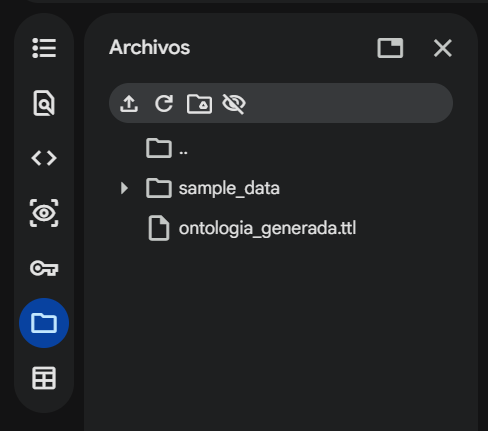

Luego, busque cualquier superheroe o supervillano instanciado, y pegué debajo de este al nuevo villano Magneto.

Con esto, el sistema experto leerá el .ttl y te dejará poder adivinar a magneto.
NOTA: Se debe haber ejecutado el módulo de ontología primero para que se cree el archivo de "ontologia_generada.ttl"